# ETH Dataset Composition and Exploratory Analysis

## Objective

This notebook aims to analyze the **overall composition, structure, and quality** of the generated ETH volume and dollar bar datasets.

The analysis focuses on examining the available features, their distributions, missing values, data coverage, and potential inconsistencies.

Unlike the previous notebook, which focused on the statistical properties of bar returns, this notebook provides a broader **exploratory data analysis (EDA)** of the datasets and their features.

The goal is to assess dataset completeness, identify potential data quality issues, and understand the characteristics of the available features before proceeding to machine learning experiments.

In [1]:
from pathlib import Path
import pandas as pd

def find_project_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "data/crypto_dataset_pipeline/crypto_dataset.py").exists():
            return path
    raise FileNotFoundError("QuantForge project root not found")

ROOT = find_project_root()
DATASETS_DIR = ROOT / "data/crypto_dataset_pipeline/data/datasets"

In [2]:
# Load the datasets
volume_25 = pd.read_parquet(DATASETS_DIR / "9ed666cb7603b0b1/volume.parquet")
volume_50 = pd.read_parquet(DATASETS_DIR / "f42c8eca7e1d67cf/volume.parquet")
volume_100 = pd.read_parquet(DATASETS_DIR / "486b5b7c40ebe4fd/volume.parquet")

dollar_25 = pd.read_parquet(DATASETS_DIR / "148ef03cfd675fa4/notional.parquet")
dollar_50 = pd.read_parquet(DATASETS_DIR / "7e8a02ceb035e8f9/notional.parquet")
dollar_100 = pd.read_parquet(DATASETS_DIR / "5e4cc12bf931053c/notional.parquet")

In [3]:
def set_datetime_index(df):
    return df.set_index(
        pd.to_datetime(df["bar_end_us"], unit="us", utc=True)
    ).sort_index().rename_axis("datetime")

volume_25, volume_50, volume_100, dollar_25, dollar_50, dollar_100 = map(
    set_datetime_index,
    (volume_25, volume_50, volume_100, dollar_25, dollar_50, dollar_100)
)

In [4]:
import numpy as np
import matplotlib.pyplot as plt


def plot_feature_availability(df, dataset_name, freq="MS", chunk_size=45):
    # Percentage of non-null observations per period
    monthly_counts = df.resample(freq).count()
    total_bars = df.resample(freq).size().replace(0, np.nan)

    availability = monthly_counts.div(total_bars, axis=0) * 100

    # Features sorted by overall availability
    columns = availability.mean().sort_values(ascending=False).index
    availability = availability[columns]

    dates = availability.index.strftime("%Y-%m")

    for start in range(0, len(columns), chunk_size):
        subset = availability.iloc[:, start:start + chunk_size].T

        fig, ax = plt.subplots(
            figsize=(16, max(5, len(subset) * 0.28))
        )

        im = ax.imshow(
            subset.values,
            aspect="auto",
            interpolation="nearest",
            cmap="RdYlGn",
            vmin=0,
            vmax=100
        )

        ax.set_yticks(range(len(subset)))
        ax.set_yticklabels(subset.index, fontsize=8)

        ticks = np.arange(0, len(dates), 6)
        ax.set_xticks(ticks)
        ax.set_xticklabels(dates[ticks], rotation=45, ha="right")

        ax.set_title(
            f"{dataset_name} — Feature Availability "
            f"({start + 1}–{start + len(subset)})"
        )
        ax.set_xlabel("Date")
        ax.set_ylabel("Feature")

        cbar = fig.colorbar(im, ax=ax, pad=0.02)
        cbar.set_label("Non-null observations (%)")

        plt.tight_layout()
        plt.show()

    return availability

## Check feature availability in the dataset

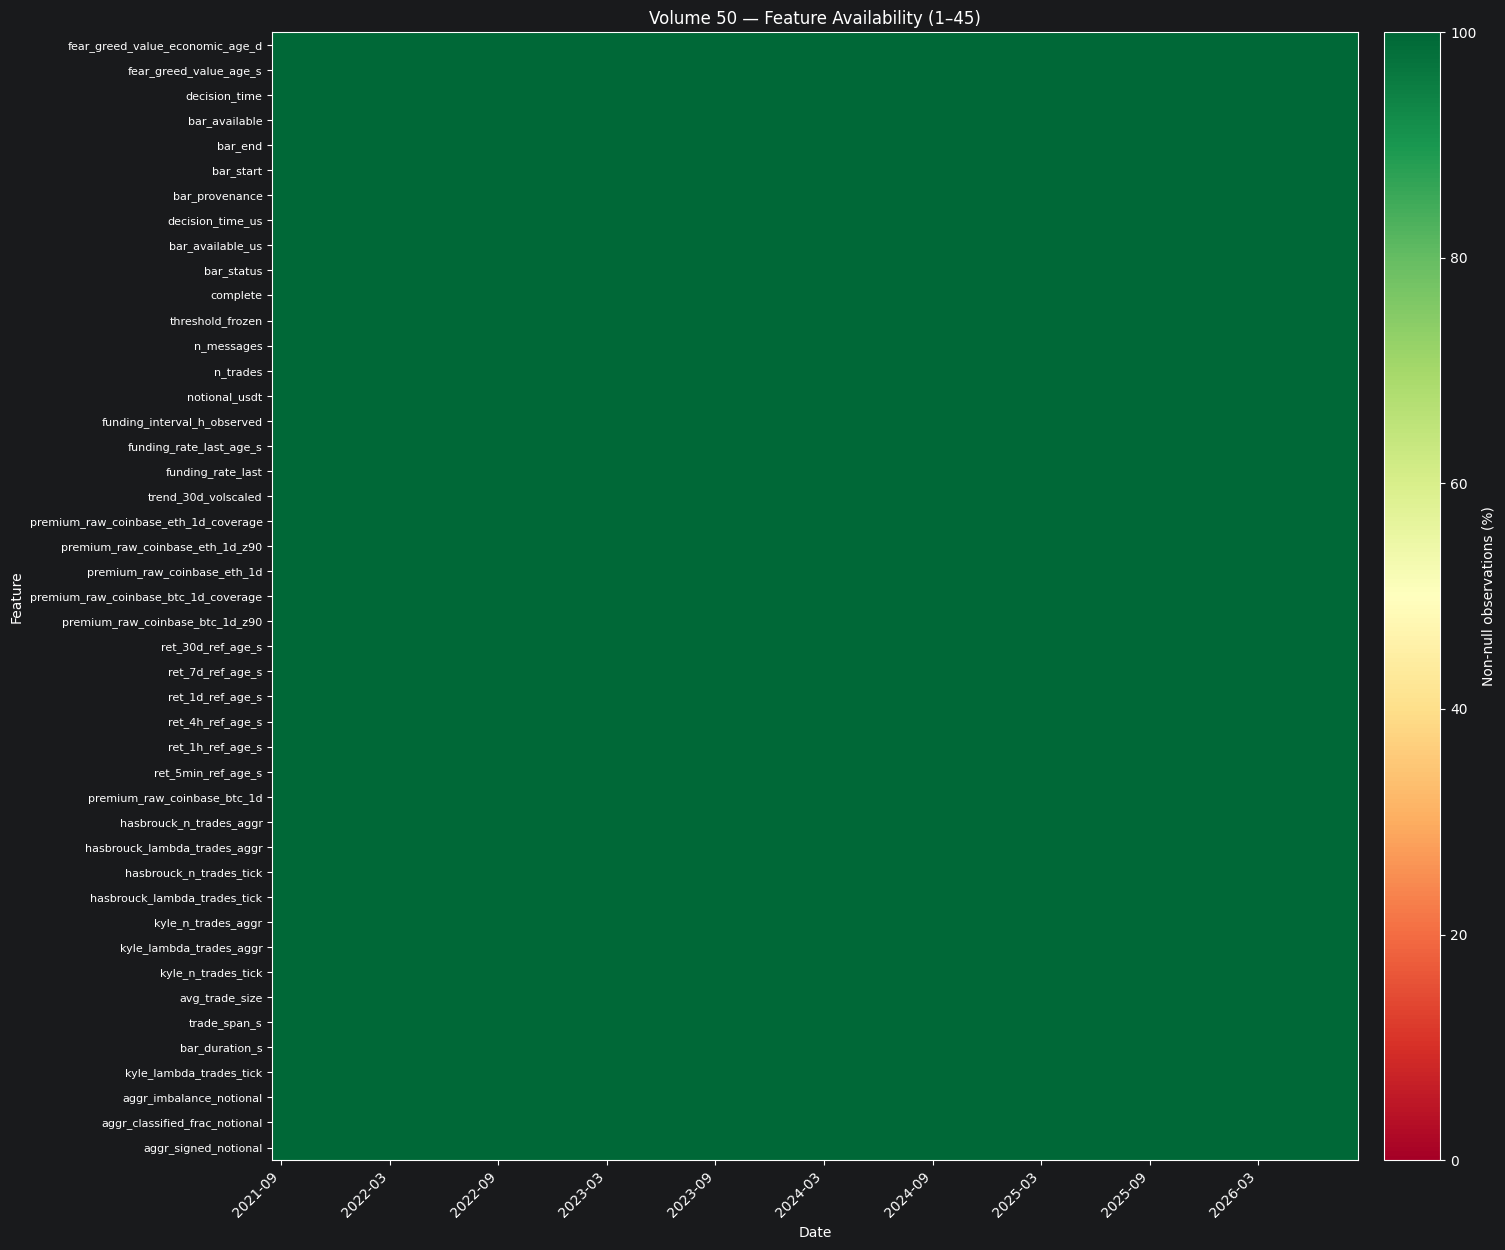

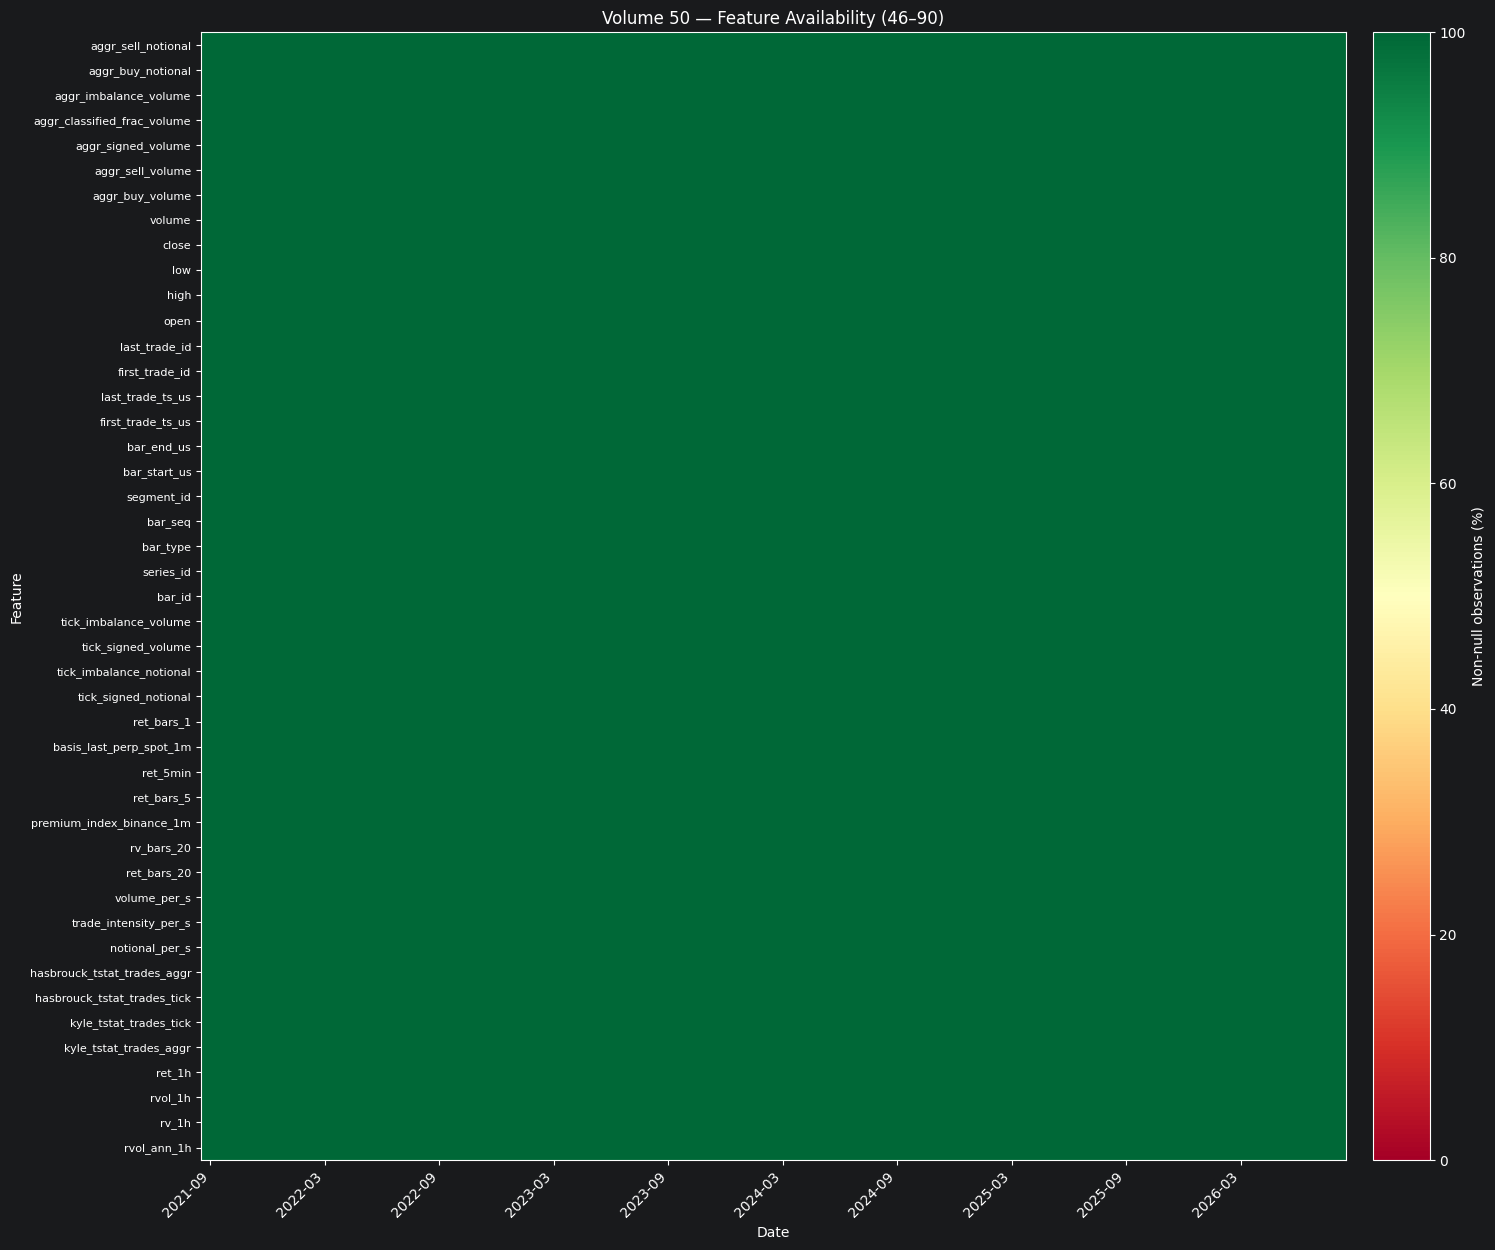

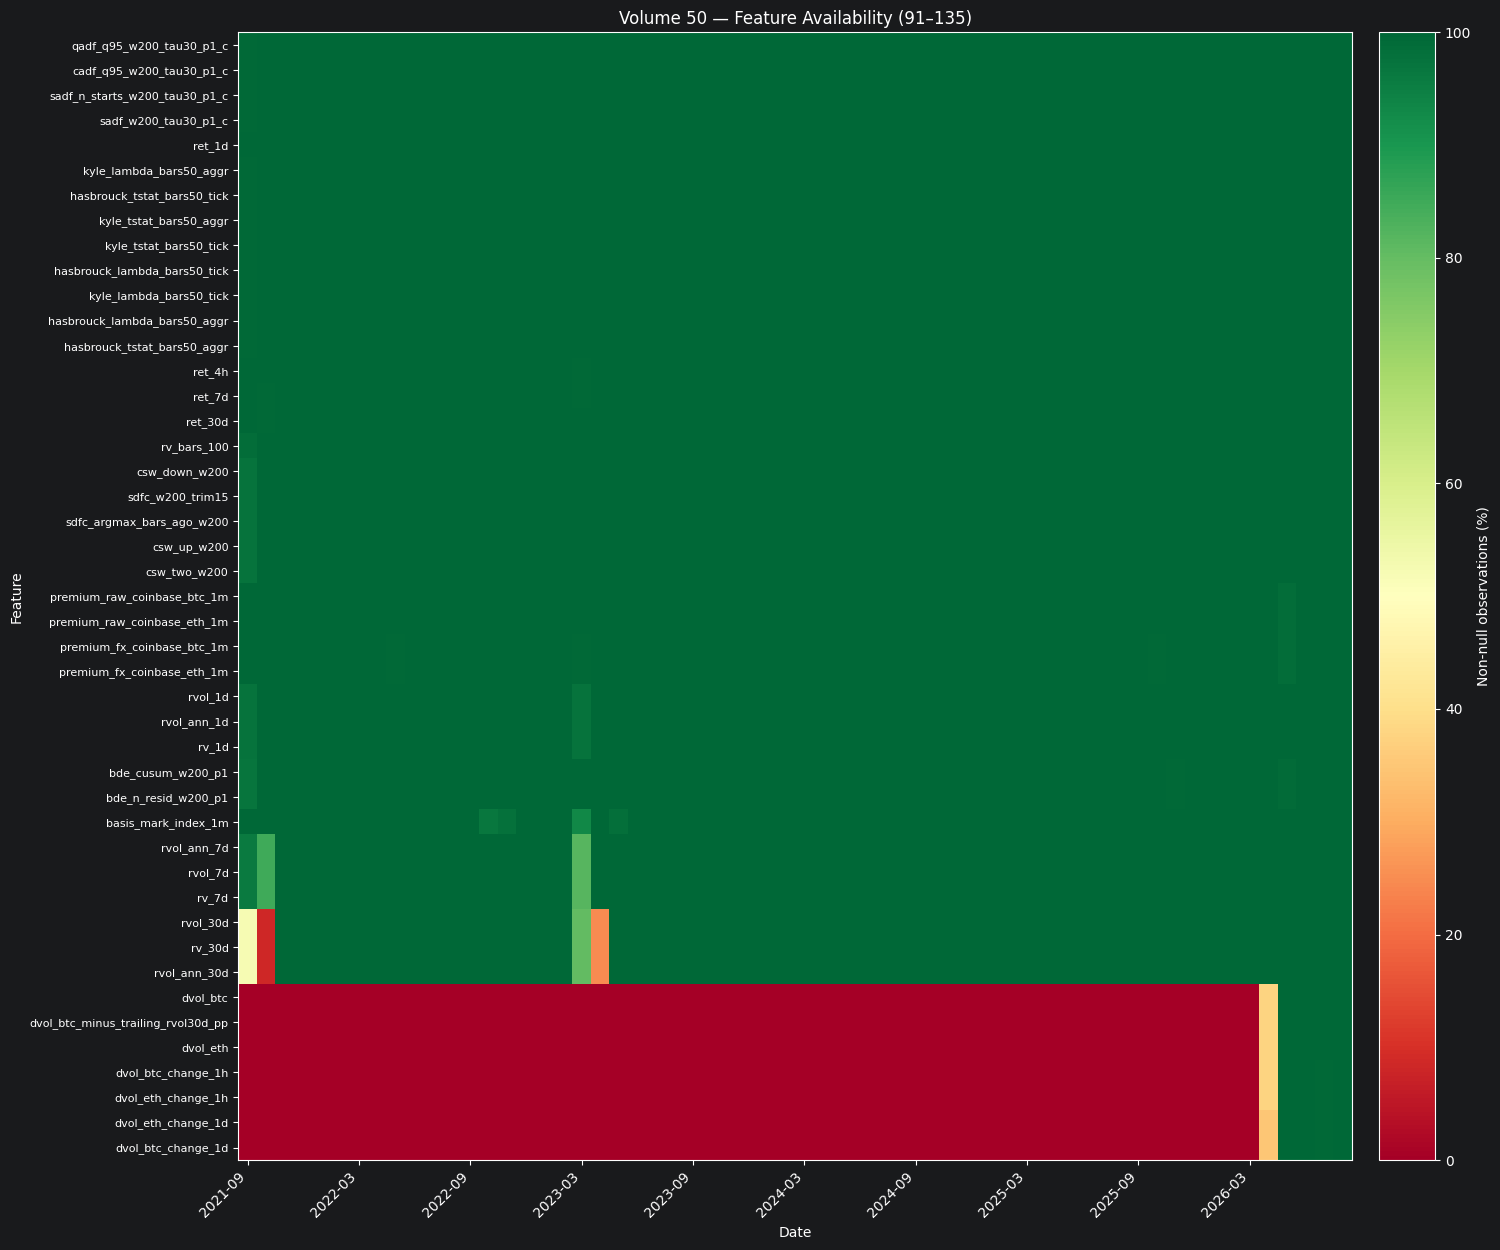

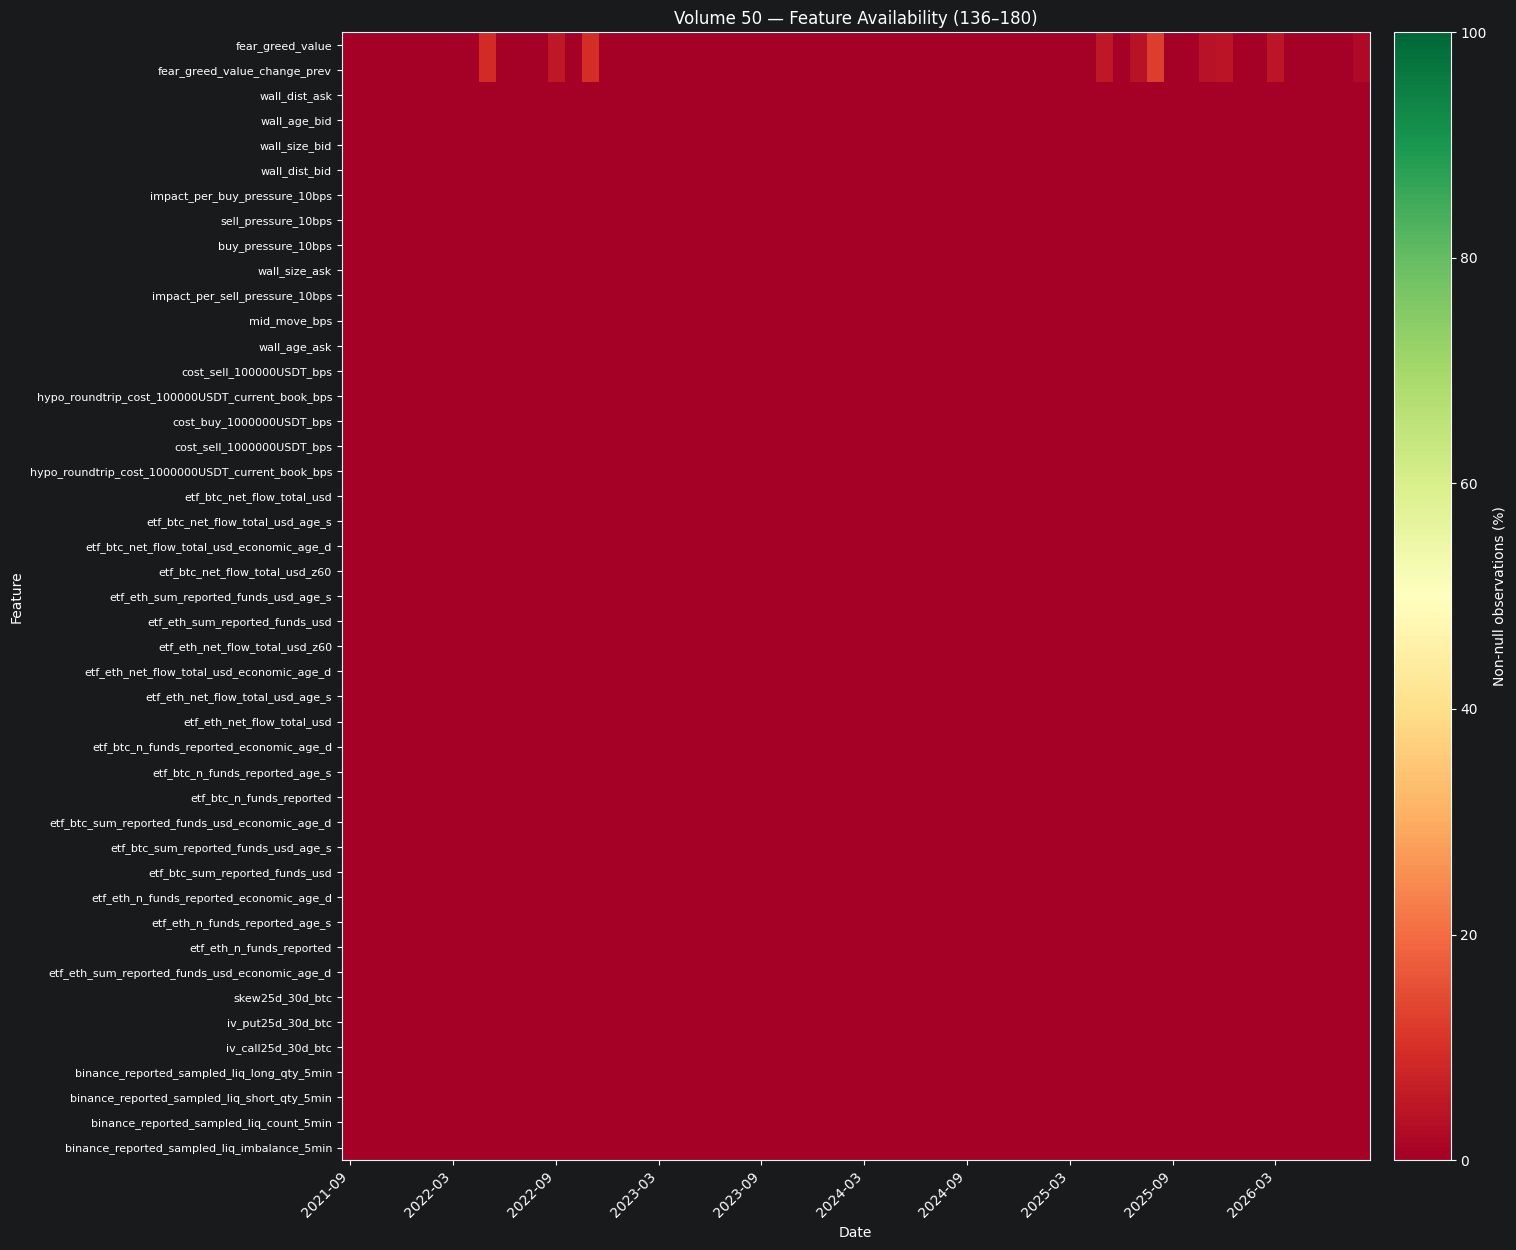

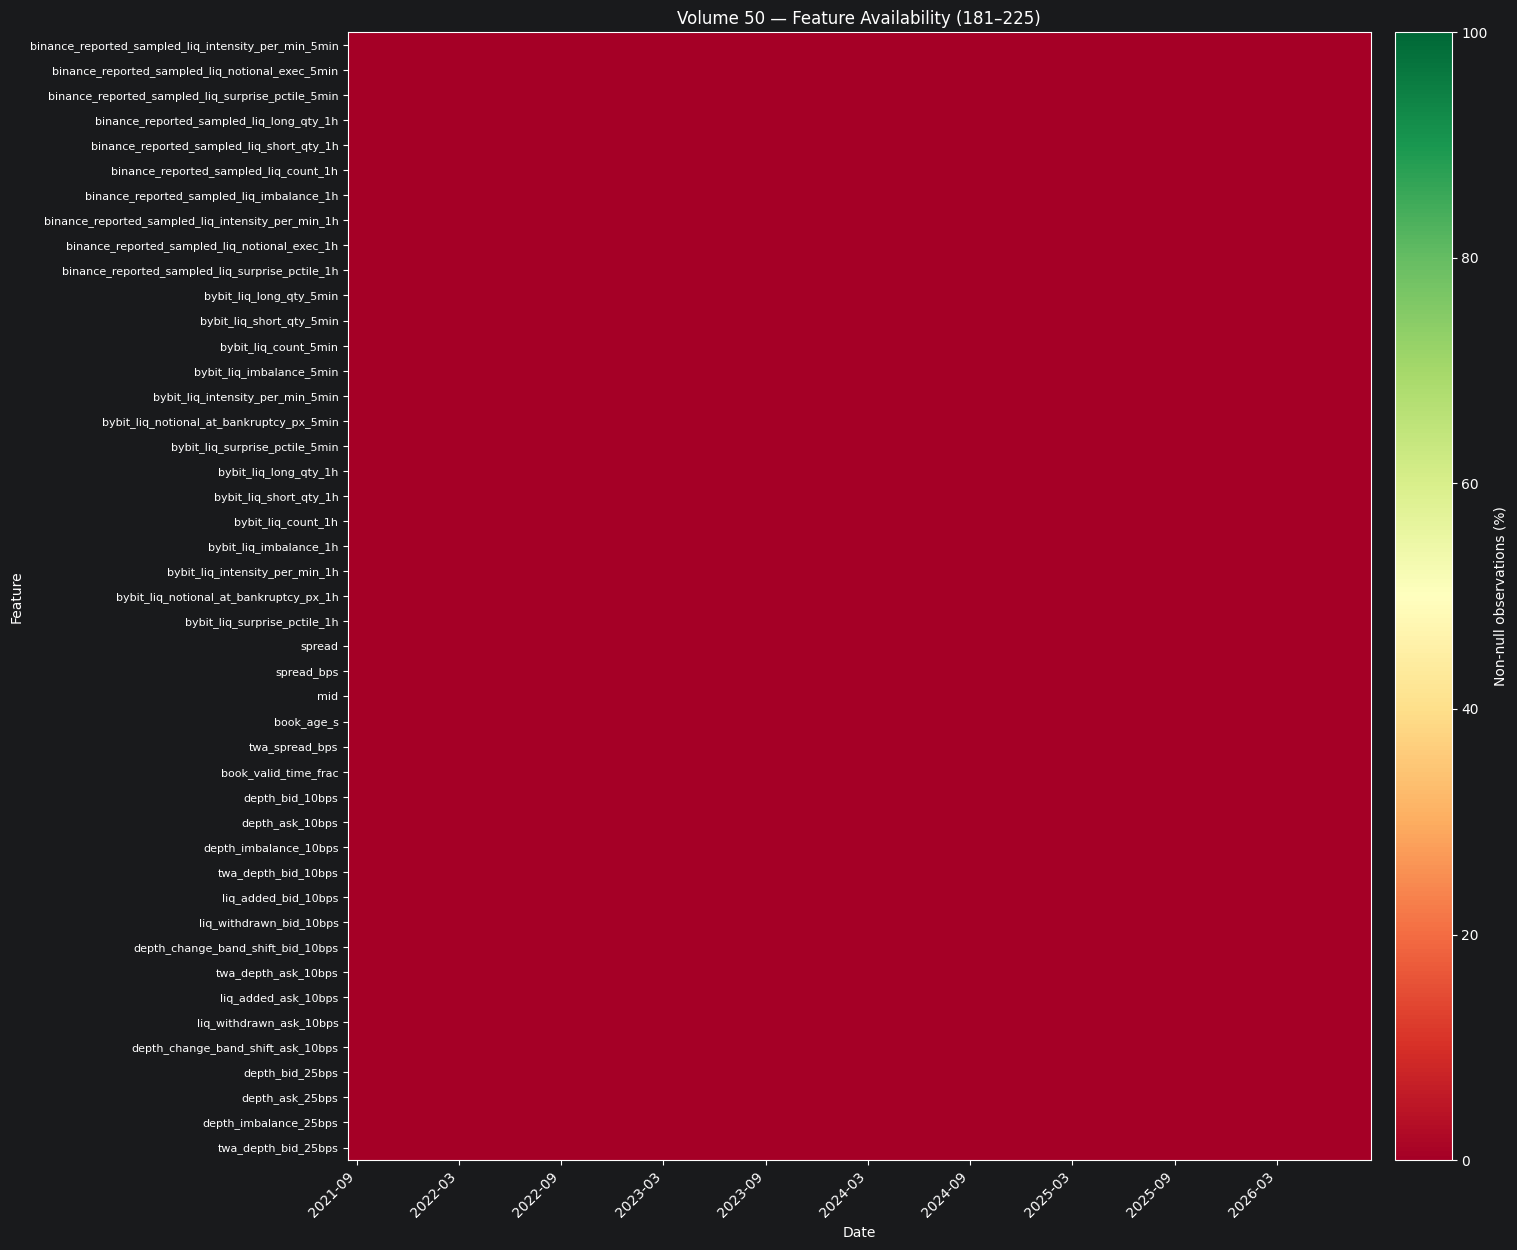

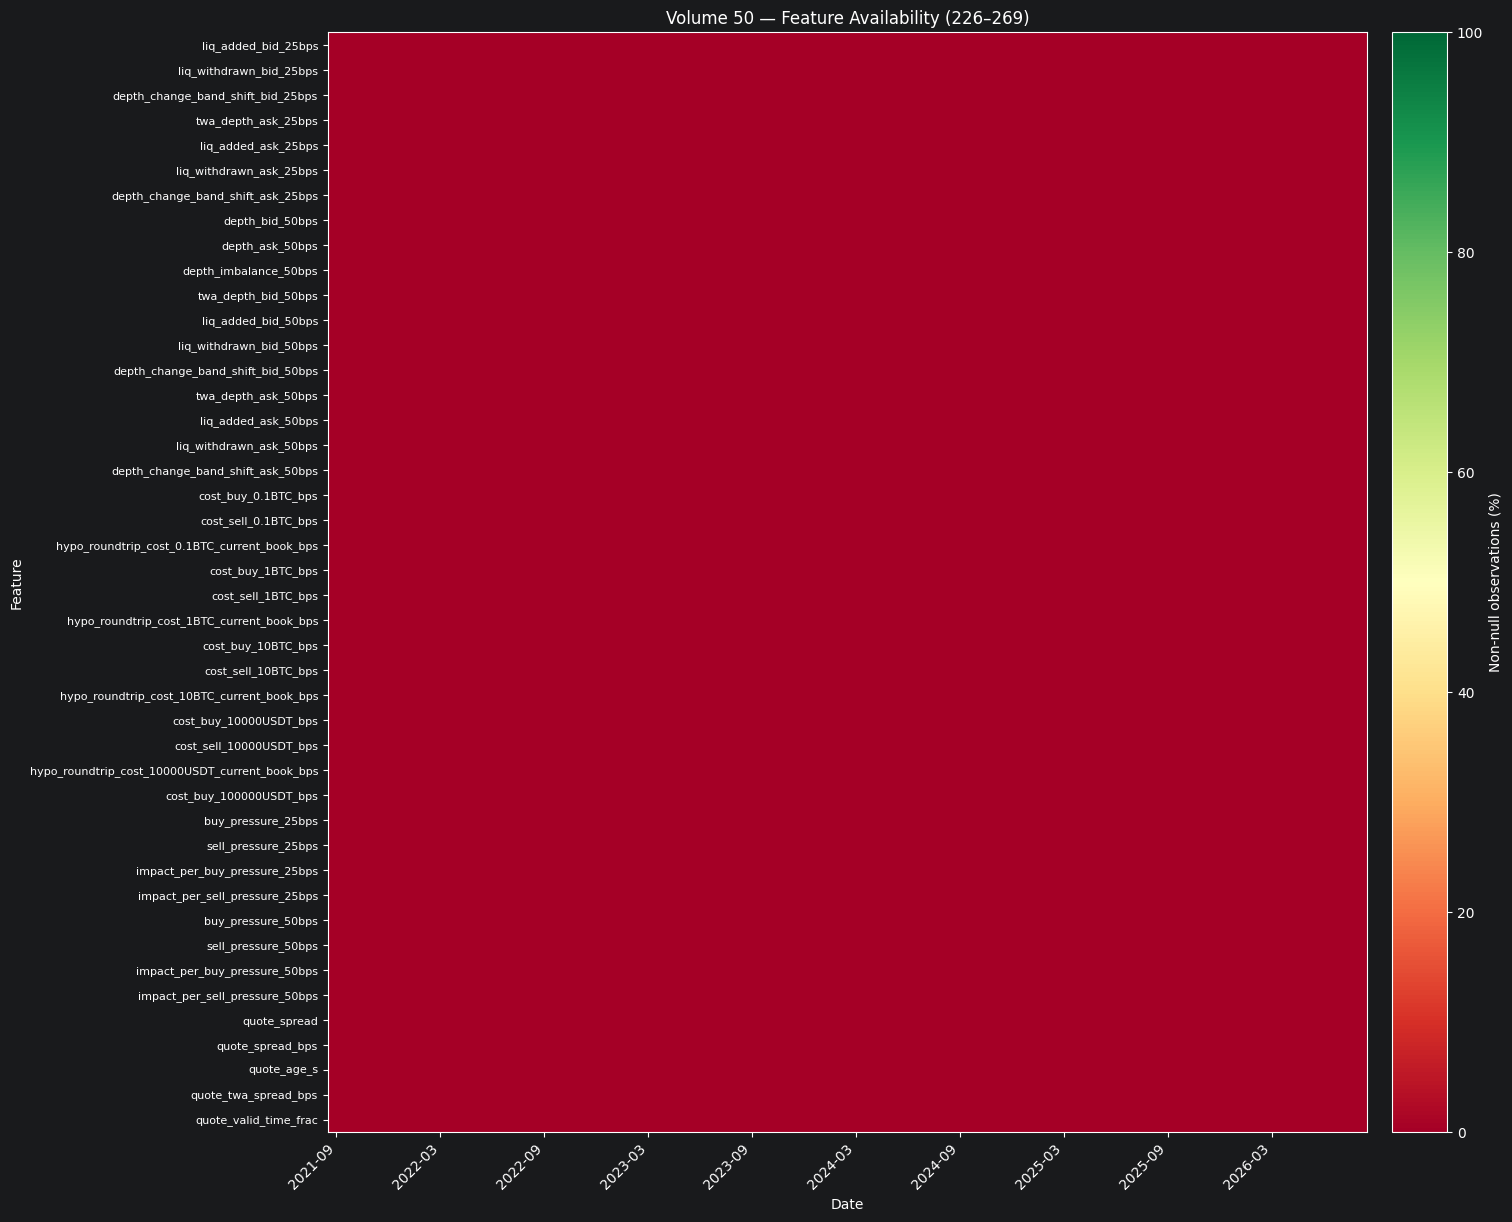

In [8]:
datasets = {
    "Volume 25": volume_25,
    "Volume 50": volume_50,
    "Volume 100": volume_100,
    "Dollar 25": dollar_25,
    "Dollar 50": dollar_50,
    "Dollar 100": dollar_100,
}

availability_volume_25 = plot_feature_availability(
    volume_25,
    "Volume 25"
)

In [13]:
def analyze_feature_coverage(df, top_n=30):
    coverage = df.notna().mean() * 100

    # Features with no valid observations
    empty_features = coverage[coverage == 0].index.tolist()

    print(f"Features with 0% coverage ({len(empty_features)}):")
    for feature in empty_features:
        print(f"  - {feature}")

    # Rarest features, excluding completely empty ones
    rare_features = (
        coverage[coverage > 0]
        .sort_values()
        .head(top_n)
        .to_frame(name="Coverage (%)")
    )

    rare_features["Non-null Count"] = df[rare_features.index].count()
    rare_features["Coverage (%)"] = rare_features["Coverage (%)"].round(4)

    print(f"\nTop {top_n} rarest features:")
    display(rare_features)

    return empty_features, rare_features


empty_features, rare_features = analyze_feature_coverage(
    volume_25,
    top_n=30
)

Features with 0% coverage (132):
  - etf_btc_net_flow_total_usd
  - etf_btc_net_flow_total_usd_age_s
  - etf_btc_net_flow_total_usd_economic_age_d
  - etf_btc_net_flow_total_usd_z60
  - etf_btc_sum_reported_funds_usd
  - etf_btc_sum_reported_funds_usd_age_s
  - etf_btc_sum_reported_funds_usd_economic_age_d
  - etf_btc_n_funds_reported
  - etf_btc_n_funds_reported_age_s
  - etf_btc_n_funds_reported_economic_age_d
  - etf_eth_net_flow_total_usd
  - etf_eth_net_flow_total_usd_age_s
  - etf_eth_net_flow_total_usd_economic_age_d
  - etf_eth_net_flow_total_usd_z60
  - etf_eth_sum_reported_funds_usd
  - etf_eth_sum_reported_funds_usd_age_s
  - etf_eth_sum_reported_funds_usd_economic_age_d
  - etf_eth_n_funds_reported
  - etf_eth_n_funds_reported_age_s
  - etf_eth_n_funds_reported_economic_age_d
  - skew25d_30d_btc
  - iv_put25d_30d_btc
  - iv_call25d_30d_btc
  - binance_reported_sampled_liq_long_qty_5min
  - binance_reported_sampled_liq_short_qty_5min
  - binance_reported_sampled_liq_count_5m

,Coverage (%),Non-null Count
fear_greed_value,1.4051,2097
fear_greed_value_change_prev,1.4051,2097
dvol_btc_change_1d,4.1810,6240
dvol_eth_change_1d,4.1810,6240
dvol_eth_change_1h,4.2072,6279
dvol_btc_change_1h,4.2072,6279
dvol_btc_minus_trailing_rvol30d_pp,4.2092,6282
dvol_eth,4.2092,6282
dvol_btc,4.2092,6282
rv_30d,96.0334,143325


In [14]:
print(empty_features)

['etf_btc_net_flow_total_usd', 'etf_btc_net_flow_total_usd_age_s', 'etf_btc_net_flow_total_usd_economic_age_d', 'etf_btc_net_flow_total_usd_z60', 'etf_btc_sum_reported_funds_usd', 'etf_btc_sum_reported_funds_usd_age_s', 'etf_btc_sum_reported_funds_usd_economic_age_d', 'etf_btc_n_funds_reported', 'etf_btc_n_funds_reported_age_s', 'etf_btc_n_funds_reported_economic_age_d', 'etf_eth_net_flow_total_usd', 'etf_eth_net_flow_total_usd_age_s', 'etf_eth_net_flow_total_usd_economic_age_d', 'etf_eth_net_flow_total_usd_z60', 'etf_eth_sum_reported_funds_usd', 'etf_eth_sum_reported_funds_usd_age_s', 'etf_eth_sum_reported_funds_usd_economic_age_d', 'etf_eth_n_funds_reported', 'etf_eth_n_funds_reported_age_s', 'etf_eth_n_funds_reported_economic_age_d', 'skew25d_30d_btc', 'iv_put25d_30d_btc', 'iv_call25d_30d_btc', 'binance_reported_sampled_liq_long_qty_5min', 'binance_reported_sampled_liq_short_qty_5min', 'binance_reported_sampled_liq_count_5min', 'binance_reported_sampled_liq_imbalance_5min', 'binance

In [15]:
print(rare_features)

                                    Coverage (%)  Non-null Count
fear_greed_value                          1.4051            2097
fear_greed_value_change_prev              1.4051            2097
dvol_btc_change_1d                        4.1810            6240
dvol_eth_change_1d                        4.1810            6240
dvol_eth_change_1h                        4.2072            6279
dvol_btc_change_1h                        4.2072            6279
dvol_btc_minus_trailing_rvol30d_pp        4.2092            6282
dvol_eth                                  4.2092            6282
dvol_btc                                  4.2092            6282
rv_30d                                   96.0334          143325
rvol_ann_30d                             96.0334          143325
rvol_30d                                 96.0334          143325
rv_7d                                    99.2375          148107
rvol_ann_7d                              99.2375          148107
rvol_7d                  

In [16]:
len(volume_25.columns)

269